# Generalized Wordle Game Using MyQLM

COE 530 PA2

pip install the stuff

In [ ]:
%pip install myqlm qiskit qiskit-aer matplotlib numpy qat-qiskit

## Classical ENcode/Decode

In [1]:
import matplotlib.pyplot as plt
import numpy as np

def word_to_binary(word: str) -> list[str]:
    """Converts a string of any length to a list of 5-bit binary strings."""
    return [np.binary_repr(ord(char) % 64, width=5) for char in word.upper()]

def binary_to_word(word_bin: str) -> str:
    """Decodes the binary result bitstring back into a classical string."""
    decoded_letters = []
    num_letters = len(word_bin) // 5 
    
    for i in range(num_letters):
        letter_bin = word_bin[i * 5 : (i + 1) * 5]
        decoded_letters.append(chr(int(letter_bin, 2) + 64))
        
    return "".join(decoded_letters)

## Create the circuit's routines

In [2]:
from qat.lang import qrout, H, CNOT, Z

@qrout
def init_routine(total_qubits: int):
    """Quantum sub-routine: Prepares data qubits in |+> and global ancilla in |->."""
    for i in range(total_qubits - 1):
        H(i) 
    
    H(total_qubits - 1)
    Z(total_qubits - 1)

@qrout
def oracle_routine(sec_strList: list[str], total_qubits: int):
    """Quantum sub-routine: Applies the phase kickback oracle for the secret word."""
    global_ancilla = total_qubits - 1
    
    for let_index, s in enumerate(sec_strList):
        for q in range(5):
            if s[q] != '0':
                data_qubit = (let_index * 5) + q
                CNOT(data_qubit, global_ancilla)

@qrout
def final_h_routine(num_data_qubits: int):
    """Quantum sub-routine: Applies final Hadamard gates to the data qubits."""
    for i in range(num_data_qubits):
        H(i)

@qrout
def build_wordle_routine(sec_strList: list[str]):
    """Main builder: Stitches initialization, oracle, and final readout routines."""
    total_qubits = (len(sec_strList) * 5) + 1 
    
    # Getting the wires for the qubits, to isolate the ancilla when applying the final H gates
    all_qubits = range(total_qubits)
    
    # Apply sub-routines sequentially to their specific target wires
    init_routine(total_qubits)(*all_qubits)
    oracle_routine(sec_strList, total_qubits)(*all_qubits)
    
    # Apply the final routine ONLY to the data qubits
    final_h_routine(total_qubits - 1)(*all_qubits[:-1])

## Defining the simulator
I am using Qiskit's AerSimulator, as MyQLM doesn't provide MPS simulator and my poor PC doesn't have enough RAM

In [3]:
from qat.lang import QRoutine as QR, Program
from qat.qiskit.converters import qaptiva_to_qiskit
from qat.qpus import get_default_qpu
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit_aer import AerSimulator

def _run_qiskit_mps(routine: QR) -> tuple[str, dict]:
    """Internal handler: Prepares and runs the routine on Qiskit's AerSimulator."""
    circuit = routine.to_circ()
    data_qubits = circuit.nbqbits - 1 
    
    qiskit_circuit = qaptiva_to_qiskit(circuit)
    qiskit_circuit.add_register(ClassicalRegister(data_qubits, 'c'))

    for i in range(data_qubits):
        qiskit_circuit.measure(i, i) 
            
    simulator = AerSimulator(method='matrix_product_state')
    result = simulator.run(qiskit_circuit).result()
    raw_counts = result.get_counts(qiskit_circuit)
    
    # Normalize Qiskit's little-endian output to big-endian
    counts = {}
    for bitstring, count in raw_counts.items():
        normalized_bitstring = bitstring[::-1]
        counts[normalized_bitstring] = count
    
    word_bin = max(counts, key=counts.get)
    return word_bin, counts

def _run_myqlm_linalg(routine: QR) -> tuple[str, dict]:
    """Internal handler: Prepares and runs the routine natively on MyQLM."""
    prog = Program()
    qbits = prog.qalloc(routine.nbqbits)
    prog.apply(routine, qbits)
    circuit = prog.to_circ()
    
    data_qubits = range(routine.nbqbits - 1)
    job = circuit.to_job(qubits=data_qubits)
    
    qpu = get_default_qpu() 
    result = qpu.submit(job)
    
    counts = {}
    for sample in result:
        bitstring = str(sample.state).replace('|', '').replace('>', '')
        counts[bitstring] = int(sample.probability * 1024)
        
    word_bin = max(counts, key=counts.get)
    return word_bin, counts

def simulate_quantum_circuit(routine: QR, backend: str = 'myqlm') -> tuple[str, dict]:
    """
    Unified router function to easily swap quantum simulators.
    
    Supported backends:
      - 'myqlm'  : Uses Native LinAlg (High RAM, Exact Precision)
      - 'qiskit' : Uses AerSimulator MPS (Low RAM, Tensor Networks)
    """
    if backend.lower() == 'qiskit':
        return _run_qiskit_mps(routine)
    elif backend.lower() == 'myqlm':
        return _run_myqlm_linalg(routine)
    else:
        raise ValueError(f"Unknown backend requested: '{backend}'. Please use 'qiskit' or 'myqlm'.")

## Run it

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display

# --- Configuration ---
SECRET_WORD = 'IBRAHEEMALYOUSEF'
SECRET_WORD = "APPLE"

BACKEND = "qiskit" # qiskit or myqlm

# --- Execution ---
sec_strList = word_to_binary(SECRET_WORD)
routine = build_wordle_routine(sec_strList)

# The router handles all the backend complexity automatically
word_bin, counts = simulate_quantum_circuit(routine, backend=BACKEND)
final_word = binary_to_word(word_bin)
print(f"The decoded secret word is: {final_word}")


The decoded secret word is: APPLE


## Better Viz


1. Simulation Details
Word: 'APPLE' | Engine: QISKIT | Qubits: 26

2. Quantum Circuit Logic


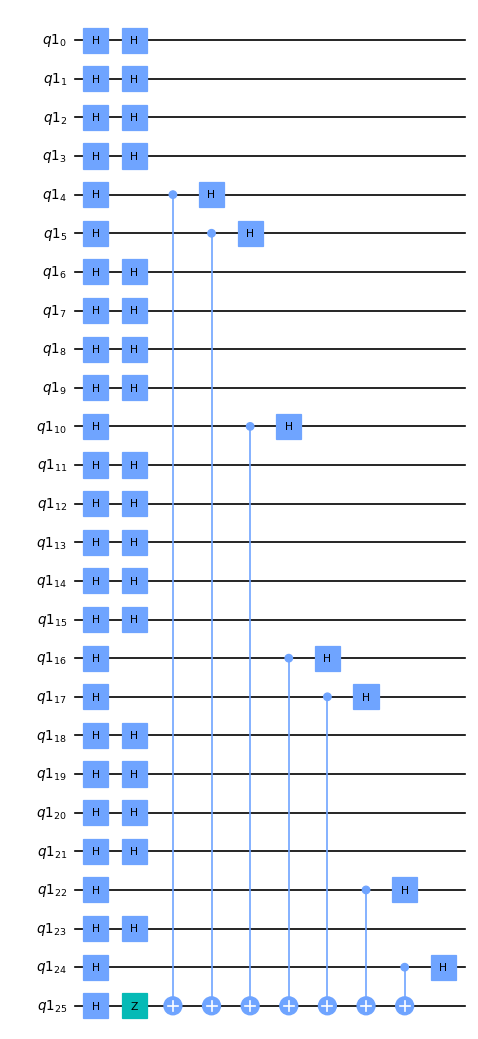


3. Measurement Results


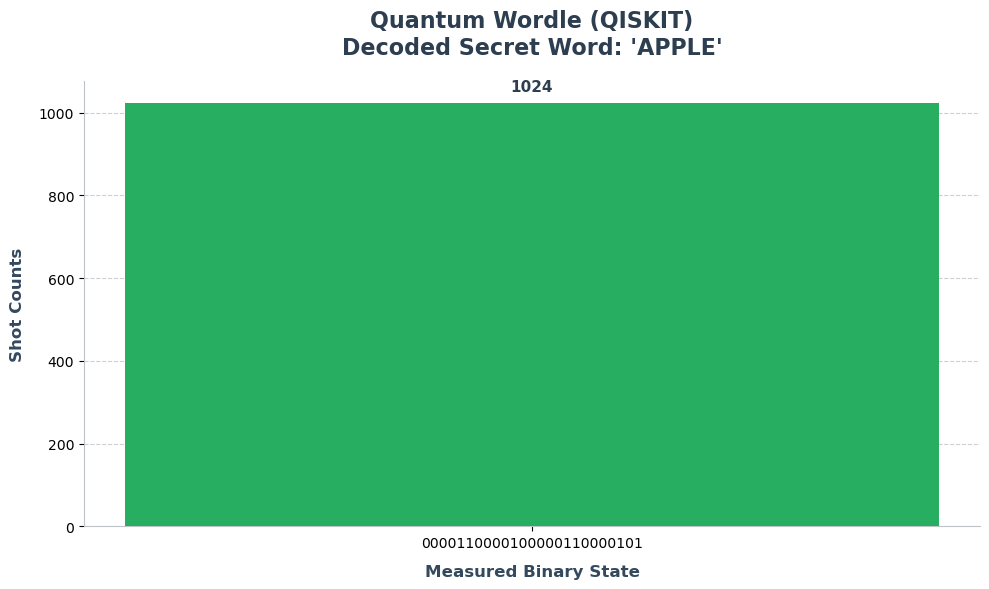

In [5]:
print(f"\n1. Simulation Details")
print(f"Word: '{SECRET_WORD}' | Engine: {BACKEND.upper()} | Qubits: {(len(sec_strList) * 5) + 1}")

print("\n2. Quantum Circuit Logic")
# We convert the routine to Qiskit strictly for the beautiful visualizer
display_circuit = qaptiva_to_qiskit(routine.to_circ())
display(display_circuit.draw(output='mpl', style='clifford', scale=0.6, fold=40))

print("\n3. Measurement Results")
fig, ax = plt.subplots(figsize=(10, 6))

sorted_counts = dict(sorted(counts.items(), key=lambda item: item[1], reverse=True))
states = list(sorted_counts.keys())
values = list(sorted_counts.values())

colors = ['#27ae60' if i == 0 else '#bdc3c7' for i in range(len(states))]
bars = ax.bar(states, values, color=colors, width=0.4, zorder=3)

ax.grid(axis='y', linestyle='--', alpha=0.6, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#bdc3c7')
ax.spines['bottom'].set_color('#bdc3c7')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + (max(values)*0.02),
            f"{yval}", ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2c3e50')

ax.set_xlabel("Measured Binary State", fontsize=12, fontweight='bold', color='#34495e', labelpad=10)
ax.set_ylabel("Shot Counts", fontsize=12, fontweight='bold', color='#34495e', labelpad=10)
plt.xticks(rotation=45 if len(states) > 3 else 0, fontsize=10)

ax.set_title(f"Quantum Wordle ({BACKEND.upper()})\nDecoded Secret Word: '{final_word}'",
             fontsize=16, fontweight='heavy', color='#2c3e50', pad=20)

plt.tight_layout()
plt.show()